# Route Clustering
Route-level features, KMeans (elbow + silhouette), label clusters, list slow and congested routes.


In [1]:
# Cell 1: setup
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import f_oneway
from src.config import *
from src.clustering import *


In [2]:
# Cell 2: load data and compute adjusted lead time
df = pd.read_csv(CLEAN_FILE)
df = add_adjusted_lead(df)
print("Std raw lead time:     ", round(df[TARGET].std(), 1))
print("Std adjusted lead time:", round(df["lead_adj"].std(), 1))
print("Mean adjusted (should be ~0):", round(df["lead_adj"].mean(), 2))

Std raw lead time:      298.6
Std adjusted lead time: 183.3
Mean adjusted (should be ~0): -0.36


In [3]:
# Cell 3: build the route table (route = factory x state)
routes = build_table(df, ["factory", "state"])
print(routes.shape)
print(routes["orders"].describe().round(1))
routes.head()

(62, 12)
count     62.0
mean      61.0
std       81.3
min       10.0
25%       17.0
50%       31.0
75%       67.0
max      449.0
Name: orders, dtype: float64


,factory,state,orders,mean_lead,mean_lead_adj,std_lead_adj,share_slow,avg_distance_km,sales,profit,profit_margin,log_orders
0,Lot's O' Nuts,Alberta,12,1347.750000,35.012097,146.343805,0.500000,2371.483835,146.72,101.42,0.691249,2.484907
1,Lot's O' Nuts,Arizona,38,1355.078947,-7.286056,201.883547,0.552632,99.338479,477.45,332.85,0.697141,3.637586
2,Lot's O' Nuts,Arkansas,14,1263.000000,-104.246207,159.013699,0.214286,1801.583529,184.45,128.25,0.695310,2.639057
3,Lot's O' Nuts,California,449,1371.619154,-10.116080,180.059047,0.496659,809.098947,6057.44,4184.04,0.690727,6.107023
4,Lot's O' Nuts,Colorado,37,1360.837838,22.176418,194.756086,0.513514,899.212083,521.53,359.33,0.688992,3.610918


In [4]:
# Cell 4: are route differences real, or just noise?
groups = [g["lead_adj"].values for _, g in df.groupby(["factory", "state"]) if len(g) >= MIN_ROUTE_ORDERS]
print("Routes tested:", len(groups))
print("ANOVA (factory x state): p =", round(f_oneway(*groups).pvalue, 4))
groups_r = [g["lead_adj"].values for _, g in df.groupby(["factory", "region"])]
print("ANOVA (factory x region): p =", round(f_oneway(*groups_r).pvalue, 4))

Routes tested: 62
ANOVA (factory x state): p = 0.0
ANOVA (factory x region): p = 0.5346


In [5]:
# Cell 5: choose k and cluster
best_k, scores = choose_k(routes)
print(scores)
print("Chosen k:", best_k)
routes = cluster_routes(routes, best_k)
routes["cluster"].value_counts().sort_index()

   k  silhouette   inertia
0  2      0.2079  244.7654
1  3      0.2426  197.0852
2  4      0.2467  168.2004
3  5      0.2345  142.2460
4  6      0.2319  121.2686
Chosen k: 4


cluster
0    23
1    27
2    11
3     1
Name: count, dtype: int64

In [6]:
# Cell 6: profile each cluster (0 = fastest ... slowest)
cols = ["orders", "mean_lead", "mean_lead_adj", "std_lead_adj", "share_slow",
        "avg_distance_km", "profit_margin"]
routes.groupby("cluster")[cols].mean().round(2)

,orders,mean_lead,mean_lead_adj,std_lead_adj,share_slow,avg_distance_km,profit_margin
cluster,,,,,,,
0,118.39,1345.79,-7.82,185.65,0.51,2602.61,0.68
1,31.04,1367.70,5.75,185.59,0.54,1172.27,0.66
2,18.82,1353.74,9.83,146.96,0.51,2359.97,0.69
3,14.00,1481.14,27.19,192.98,0.64,2579.34,0.50


In [7]:
# Cell 7: flag slow routes and list them
routes = flag_slow_routes(routes)
print("Slow routes:", routes["slow_flag"].sum(), "of", len(routes))
(routes[routes["slow_flag"]]
 .sort_values("mean_lead_adj", ascending=False)
 [["factory", "state", "orders", "mean_lead_adj", "share_slow", "avg_distance_km", "cluster"]]
 .head(15))

Slow routes: 16 of 62


,factory,state,orders,mean_lead_adj,share_slow,avg_distance_km,cluster
5,Lot's O' Nuts,Connecticut,15,113.464937,0.866667,3553.905834,2
12,Lot's O' Nuts,Maryland,26,107.673133,0.730769,3200.058709,2
56,Wicked Choccy's,Rhode Island,11,89.285791,0.727273,1364.182835,1
47,Wicked Choccy's,Minnesota,21,74.868379,0.761905,1871.790699,1
15,Lot's O' Nuts,Minnesota,20,74.402201,0.700000,2087.326347,1
16,Lot's O' Nuts,Missouri,23,73.785612,0.695652,1861.253076,2
41,Wicked Choccy's,Indiana,17,68.707446,0.705882,981.167442,1
7,Lot's O' Nuts,Florida,88,51.238601,0.670455,2932.370699,0
49,Wicked Choccy's,New Jersey,18,50.193524,0.666667,1087.050126,1
38,Wicked Choccy's,Florida,71,49.143682,0.704225,482.693698,1


In [8]:
# Cell 8: region x product congestion
rp = build_table(df, ["region", "product"])
rp = flag_congested(rp)
print("Region-product combos:", len(rp), "| congested:", rp["congested_flag"].sum())
(rp[rp["congested_flag"]]
 .sort_values("congestion_score", ascending=False)
 [["region", "product", "orders", "mean_lead_adj", "congestion_score"]])

Region-product combos: 27 | congested: 3


,region,product,orders,mean_lead_adj,congestion_score
24,Pacific,Wonka Bar - Triple Dazzle Caramel,256,20.987742,2.002545
4,Atlantic,Wonka Bar - Nutty Crunch Surprise,206,24.785896,1.625650
15,Interior,Wonka Bar - Milk Chocolate,197,17.670825,1.207955


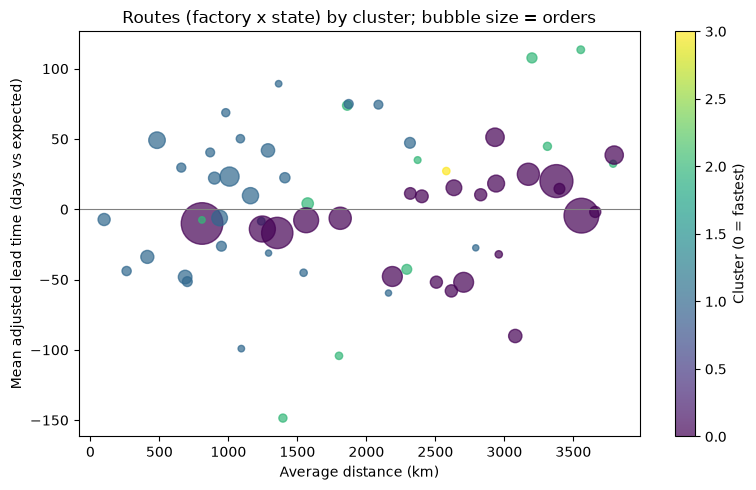

In [9]:
# Cell 9: plot clusters and save the figure
plt.figure(figsize=(8, 5))
sc = plt.scatter(routes["avg_distance_km"], routes["mean_lead_adj"],
                 c=routes["cluster"], cmap="viridis", s=routes["orders"] * 2, alpha=0.7)
plt.axhline(0, color="grey", lw=0.8)
plt.xlabel("Average distance (km)")
plt.ylabel("Mean adjusted lead time (days vs expected)")
plt.title("Routes (factory x state) by cluster; bubble size = orders")
plt.colorbar(sc, label="Cluster (0 = fastest)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "route_clusters.png", dpi=150)
plt.show()

In [10]:
# Cell 10: save and verify
routes.to_csv(ROUTE_CLUSTERS_FILE, index=False)
rp.to_csv(REGION_PRODUCT_FILE, index=False)

chk_routes = pd.read_csv(ROUTE_CLUSTERS_FILE)
chk_rp = pd.read_csv(REGION_PRODUCT_FILE)
assert len(chk_routes) >= 10, "Too few routes: lower MIN_ROUTE_ORDERS in config.py"
assert chk_routes["cluster"].nunique() >= 2, "Clustering produced a single cluster"
assert not chk_routes[CLUSTER_FEATURES].isna().any().any(), "NaNs in cluster features"
assert abs(df["lead_adj"].mean()) < 5, "Adjusted lead time is not centred near 0"
assert (FIGURES_DIR / "route_clusters.png").exists()
print("STEP 4 CHECKS PASSED | routes:", len(chk_routes),
      "| clusters:", chk_routes["cluster"].nunique(),
      "| slow routes:", int(chk_routes["slow_flag"].sum()),
      "| congested region-products:", int(chk_rp["congested_flag"].sum()))

STEP 4 CHECKS PASSED | routes: 62 | clusters: 4 | slow routes: 16 | congested region-products: 3
